# 04 — Silent churn: who is shrinking without cancelling, can we see it coming, and which accounts CS should work first

**Revenue Analytics · data as of 30 Sep 2026 · synthetic data** (see `docs/data_model.md`)
Request: *"Which customers are quietly downgrading? Which accounts should the CS team prioritize?"* (`docs/01_request_and_scope.md`, questions Q3–Q4)

In [1]:
import pandas as pd
from saas_rev import marts, theme
from saas_rev.nbutil import md, setup, show
from saas_rev.analysis import silent_churn as SC
from saas_rev.theme import money, pct, pts
setup()
k = SC.key_numbers()
km = marts.read_key_numbers("metrics")
P, F, R, W = k["profile"], k["followup"], k["rule"], k["watchlist"]
D = k["doc_default_rule"]
Q, BM, BA = R["by_quarter"], R["by_billing_period"]["monthly"], R["by_billing_period"]["annual"]

## TL;DR

In [2]:
md(f"""
- **{k['flagged_accounts']:,} paying accounts are silently contracting at 30 Sep 2026: {k['silent_accounts']:,} silent and {k['saved_accounts']:,} kept by a CS save offer.**
  They still pay **{money(k['arr_at_risk'], 2)} ARR ({pct(k['arr_at_risk_share_of_arr'])} of ARR)** and have already given up **{money(k['lost_arr'])}** against their 6-month peak
  (median decline {pct(k['median_decline_pct'], 0)}, billing-neutral). The list grew from {k['flagged_accounts_2026_06']:,} accounts ({money(k['arr_at_risk_2026_06'])}) in June.
- **It is a Technology story.** Technology is {pct(P['technology_share_flagged'], 0)} of the flagged accounts vs {pct(P['technology_share_other'], 0)} of other paying accounts
  ({P['technology_index']:.1f}× over-represented); its flag rate went from {pct(P['technology_flag_rate_2026_06'], 1)} in June to {pct(P['technology_flag_rate'], 1)} in September,
  while every other industry stayed near {pct(P['other_flag_rate'], 1)}. The money left as **seat cuts at monthly billing dates** ({k['contraction_mix']['seat_cut_monthly_accounts']} of
  {k['flagged_accounts']} accounts; median cut {pct(k['contraction_mix']['median_seat_cut_pct'], 0)} of seats), not plan downgrades ({k['contraction_mix']['plan_downgrade_accounts']}).
  Consistent with the hiring slowdown CSMs described — the seat cuts are now quantified; the sector link is a correlation (no account-level headcount data).
- **The loss is mostly already booked.** In history (Jan 2025 – Mar 2026), newly flagged silent accounts churned within 6 months at {pct(F['silent_churn_6m'], 0)}
  (95% interval {pct(F['silent_churn_6m_lo'], 0)}–{pct(F['silent_churn_6m_hi'], 0)}) vs {pct(F['unflagged_matched_churn_6m'], 0)} for unflagged accounts of the same
  segment, billing period and tenure — not a clear excess. The silent list is a revenue-recovery list, not a churn list.
- **Early warning works on utilization alone.** The rule now in 02 §9.1 (v1.2) — 13-week seat utilization below {pct(R['utilization_threshold'], 0)} — has precision {pct(R['precision'], 0)}
  (95% interval {pct(R['precision_lo'], 0)}–{pct(R['precision_hi'], 0)}, accounts resampled), recall {pct(R['recall'], 0)} ({pct(R['recall_lo'], 0)}–{pct(R['recall_hi'], 0)}) and lift {R['lift']:.1f}× over the
  {pct(R['base_rate'], 0)} base rate on {R['eligible_rows']:,} eligible account-months, and it held in every quarter from {Q['first_quarter']} to {Q['last_quarter']}
  (precision {pct(Q['precision_min'], 0)}–{pct(Q['precision_max'], 0)}, recall {pct(Q['recall_min'], 0)}–{pct(Q['recall_max'], 0)}). Median lead {BM['lead_median']:.0f} month-ends for
  monthly-billed and {BA['lead_median']:.0f} for annual-billed accounts (the most the back-test window allows); {pct(R['share_lead_ge2'], 0)} of caught events were flagged at least 2 month-ends ahead (the pooled median,
  {R['lead_median']:.0f}, moves with the monthly / annual mix, so the by-billing figures are the ones to quote).
  The v1.0 draft (utilization < 60% **and** WAU trend ≤ −15%) has lift {D['lift']:.2f}× and recall {pct(D['recall'], 0)}: the WAU condition removes flags without making them more accurate.
- **Watchlist: {W['accounts']:,} accounts, {money(W['arr_at_stake'])} ARR at stake** (current ARR × the flag's historical hit rate); {W['csm_queue']:,} are CSM-covered.
  The top {SC.CSM_CAPACITY_PER_QUARTER} CSM-covered accounts cover {pct(W['top120_csm_share_of_arr_at_stake'], 0)} of ARR at stake — above the 60% trigger in the scope doc,
  so the Q1 2027 coverage plan should be CSM-led for that queue and digital for the rest. {W['renewals_within_120d']} accounts ({money(W['renewal_arr_within_120d'])} ARR)
  have an annual renewal within 120 days and lead each queue, the {W['renewals_under_45d']} renewing in under {W['urgent_renewal_days']} days first, soonest first.
  {W['top120_csm_rising_usage']} of the top {SC.CSM_CAPACITY_PER_QUARTER} CSM accounts show WAU up {pct(SC.WAU_UP_CODE, 0)}+ on under-used seats: a seat-count conversation, not a save.
""")


- **324 paying accounts are silently contracting at 30 Sep 2026: 307 silent and 17 kept by a CS save offer.**
  They still pay **$1.07M ARR (4.3% of ARR)** and have already given up **$649K** against their 6-month peak
  (median decline 29%, billing-neutral). The list grew from 162 accounts ($571K) in June.
- **It is a Technology story.** Technology is 60% of the flagged accounts vs 23% of other paying accounts
  (2.6× over-represented); its flag rate went from 3.8% in June to 18.3% in September,
  while every other industry stayed near 4.3%. The money left as **seat cuts at monthly billing dates** (240 of
  324 accounts; median cut 25% of seats), not plan downgrades (20).
  Consistent with the hiring slowdown CSMs described — the seat cuts are now quantified; the sector link is a correlation (no account-level headcount data).
- **The loss is mostly already booked.** In history (Jan 2025 – Mar 2026), newly flagged silent accounts churned within 6 months at 12%
  (95% interval 9%–17%) vs 12% for unflagged accounts of the same
  segment, billing period and tenure — not a clear excess. The silent list is a revenue-recovery list, not a churn list.
- **Early warning works on utilization alone.** The rule now in 02 §9.1 (v1.2) — 13-week seat utilization below 50% — has precision 39%
  (95% interval 37%–42%, accounts resampled), recall 30% (28%–32%) and lift 2.3× over the
  17% base rate on 30,247 eligible account-months, and it held in every quarter from Q3 2024 to Q2 2026
  (precision 33%–47%, recall 26%–36%). Median lead 3 month-ends for
  monthly-billed and 6 for annual-billed accounts (the most the back-test window allows); 83% of caught events were flagged at least 2 month-ends ahead (the pooled median,
  3, moves with the monthly / annual mix, so the by-billing figures are the ones to quote).
  The v1.0 draft (utilization < 60% **and** WAU trend ≤ −15%) has lift 1.89× and recall 15%: the WAU condition removes flags without making them more accurate.
- **Watchlist: 989 accounts, $1.7M ARR at stake** (current ARR × the flag's historical hit rate); 282 are CSM-covered.
  The top 120 CSM-covered accounts cover 66% of ARR at stake — above the 60% trigger in the scope doc,
  so the Q1 2027 coverage plan should be CSM-led for that queue and digital for the rest. 134 accounts ($822K ARR)
  have an annual renewal within 120 days and lead each queue, the 32 renewing in under 45 days first, soonest first.
  23 of the top 120 CSM accounts show WAU up 20%+ on under-used seats: a seat-count conversation, not a save.


## Question
- **Q3.** Which paying customers are shrinking without cancelling ("silent churn"), how much ARR do they represent, and what do they look like?
- **Q4.** Can we see silent churn coming early enough for CS to act? Rule, back-tested precision / recall / lead time, and a ranked watchlist.

**Decision it feeds:** the Head of Customer Success's Q1 2027 coverage plan (scope doc §3): if the top 120 accounts by ARR at stake cover ≥ 60% of risk ARR, the CSM team runs proactive reviews on them and everything else goes to the digital play; otherwise capacity shifts to the digital play.

## Data
| Table (SQL file) | Grain | Used for |
|---|---|---|
| `fct_customer_mrr_monthly` (`sql/20`) | customer × month-end | billing-neutral MRR (`mrr_norm`), peaks, what happens next |
| `fct_mrr_movement_components` (`sql/22`), `fct_change_components` | continuing customer × month; plan change | which contractions are real (seats / plan / discount) and who initiated them |
| `rpt_silent_contraction` (`sql/50`) | flagged customer × month-end | the official §9 flags, reproduced here in pandas with parameters |
| `fct_account_month_features` (`sql/41`) | paying customer × month-end | utilization, WAU trend, eligibility, renewal-aware outcome labels (`label_*`, future, never used as features) |
| `int_next_renewal` (`sql/11`), `stg_customers` | subscription / account | renewal dates, owners for the watchlist |

Internal / test accounts are excluded; definitions in `docs/02_metric_definitions.md` §9, §9.1, §12, §15.

## Method
- **Silent contraction (02 §9).** Paying at month-end *t*, no open cancellation, billing-neutral MRR ≤ 80% of its peak over *t−6 … t−1*, and ≥ 1 Contraction in *t−5 … t* with a negative plan, seats or discount part (a monthly → annual switch never qualifies). *Saved — re-risk* when a contraction in the window was a CS save (`change_source = customer_success`). Re-implemented in pandas with the threshold and lookback as parameters (the dashboard's sliders) and checked against the SQL table at 20% / 6 months.
- **Profile.** Over-representation index = share of a group among flagged accounts ÷ its share among the other paying accounts at 30 Sep 2026, with counts. Contraction type = the change that cost each account the most MRR in the window, by `change_source`.
- **What happens next.** Accounts newly flagged (first month-end of a flag run) between Jan 2025 and Mar 2026, so every 6-month window is complete: share with MRR = 0 at any of the next 6 month-ends (churn), and share that churned or contracted another ≥ 10% (billing-neutral). Comparison group: unflagged paying account-months in the same period, standardised to the flagged mix of segment × billing period × tenure band. Wilson 95% intervals on the rows (the comparison group's rows are account-months, so its interval is narrower than an account-level one would be).
- **Early-warning back-test (02 §9.1).** Eligible (account, *t*): paying, no open cancellation, no Contraction in *t−2 … t* (`contraction_months_3m = 0`), outcome window complete (`label_window_complete`), and 13 complete weeks of usage (the rule needs the full window). Outcome = `label_contraction10_or_churn`: billing-neutral MRR ≤ 90% of MRR*t* at any month-end of the window — *t+1 … t+3* for monthly billing, *t+1* … the next renewal month-end (within 6 months) for annual billing. Grid: utilization 40–80% × WAU trend 0 to −40%, plus utilization-only. Metrics at the (account, month) grain; event-level and account-level recall; flags per month and distinct CSM-covered accounts per quarter; lead time = month-ends from the first flag of the uninterrupted flag run that ends closest to the outcome, to the outcome month (one run per caught event). Two checks on the chosen rule: precision / recall / base rate in each calendar quarter from Q3 2024 to Q2 2026 (the quarters with ≥ 1,500 eligible rows), and 95% account-level cluster-bootstrap intervals for precision and recall (accounts resampled with replacement, their month-ends drawn together, 1,000 draws).
- **Operating point.** Criterion fixed before looking at the grid: highest recall subject to precision ≥ 2× the base rate and ≤ 120 distinct CSM-covered accounts flagged per quarter on average (CS capacity, assumption A9; quarters Q3 2025 – Q2 2026); precision breaks ties.
- **Watchlist (02 §15).** Union of the §9 flags and the rule's flags at 30 Sep 2026; ARR at stake = current ARR × the historical hit rate of the flag bucket; priority within each queue (CSM-covered vs digital) in three tiers: annual renewals in under 45 days by date (soonest first), annual renewals within 120 days by ARR at stake, then everything else by ARR at stake. Early-warning accounts whose WAU rose 20% or more get a seat-count play (`WAU_UP_20PCT`), not an idle-seat save.

## Results
### 1. How big is it?

In [3]:
check = SC.verify_definition()
md(f"""**Definition check.** The pandas implementation at 20% / 6 months returns {check['pandas_rows']:,} flagged account-months; `rpt_silent_contraction` has {check['sql_rows']:,}.
Rows only in SQL: {check['rows_only_in_sql']}; only in pandas: {check['rows_only_in_pandas']}; class mismatches: {check['class_mismatches']}; step-count mismatches: {check['step_mismatches']};
largest difference in decline %: {check['max_abs_decline_diff']:.2e}; in lost ARR: ${check['max_abs_lost_arr_diff']:.2f}. **Exact match: {check['exact_match']}.**""")

**Definition check.** The pandas implementation at 20% / 6 months returns 2,821 flagged account-months; `rpt_silent_contraction` has 2,821.
Rows only in SQL: 0; only in pandas: 0; class mismatches: 0; step-count mismatches: 0;
largest difference in decline %: 0.00e+00; in lost ARR: $0.00. **Exact match: True.**

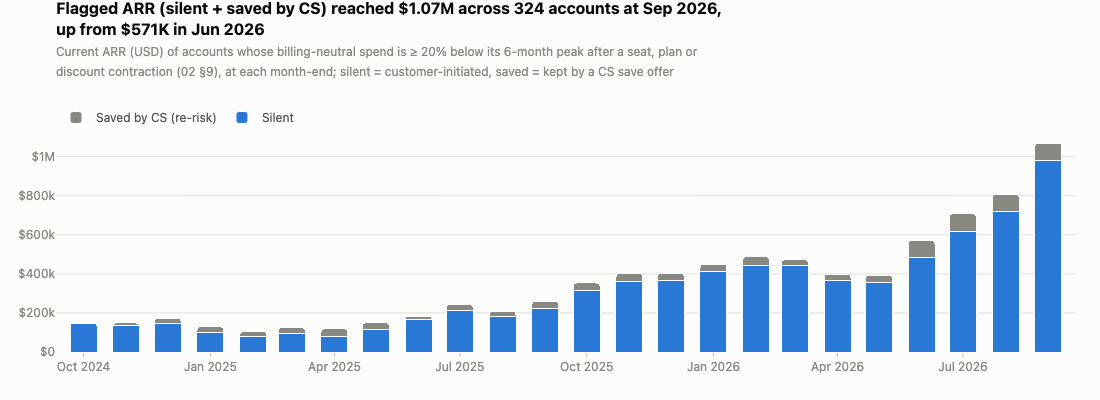

In [4]:
trend = marts.load("silent_churn__flag_trend")
show(SC.fig_flagged_trend(trend))

In [5]:
t = trend.pivot(index="month_end", columns="contraction_class", values=["accounts", "current_arr", "lost_arr"]).tail(8)
t.columns = [f"{a}_{b}" for a, b in t.columns]
t

,accounts_saved_re_risk,accounts_silent,current_arr_saved_re_risk,current_arr_silent,lost_arr_saved_re_risk,lost_arr_silent
month_end,,,,,,
2026-02-28,15.0000,120.0000,"44,304.0000","443,786.4000","51,720.0000","252,366.2400"
2026-03-31,15.0000,126.0000,"29,952.0000","442,754.4000","42,036.0000","249,564.2400"
2026-04-30,15.0000,121.0000,"32,508.0000","365,942.4000","46,284.0000","183,066.2400"
2026-05-31,14.0000,126.0000,"35,280.0000","357,686.4000","52,836.0000","186,342.2400"
2026-06-30,17.0000,145.0000,"89,508.0000","481,462.8000","133,400.1600","228,518.8800"
2026-07-31,18.0000,197.0000,"91,920.0000","616,954.8000","141,908.1600","286,910.8800"
2026-08-31,16.0000,244.0000,"89,076.0000","717,130.8000","140,972.1600","359,666.8800"
2026-09-30,17.0000,307.0000,"90,300.0000","979,891.2000","149,996.1600","499,203.8400"


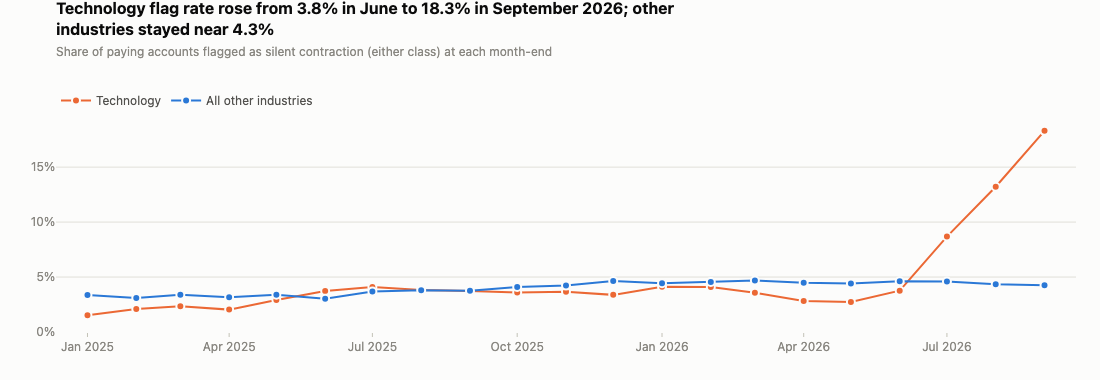

In [6]:
show(SC.fig_tech_flag_rate(marts.load("silent_churn__flag_rate_tech")))

In [7]:
md(f"""**Reading.** {k['silent_accounts']:,} silent and {k['saved_accounts']:,} saved accounts at 30 Sep 2026 pay {money(k['arr_at_risk'])} ARR today ({pct(k['arr_at_risk_share_of_arr'])} of
{money(km['arr'])}); silent accounts alone are {money(k['silent_arr'])}. Against their 6-month peak they have given up {money(k['lost_arr'])} of ARR
({money(k['silent_lost_arr'])} silent, {money(k['saved_lost_arr'])} saved). A year earlier the list was {k['flagged_accounts_2025_09']:,} accounts ({money(k['arr_at_risk_2025_09'])});
the step up since June 2026 is almost entirely Technology accounts.""")

**Reading.** 307 silent and 17 saved accounts at 30 Sep 2026 pay $1.1M ARR today (4.3% of
$24.8M); silent accounts alone are $980K. Against their 6-month peak they have given up $649K of ARR
($499K silent, $150K saved). A year earlier the list was 89 accounts ($261K);
the step up since June 2026 is almost entirely Technology accounts.

### 2. Who are they, and what did the contraction look like?

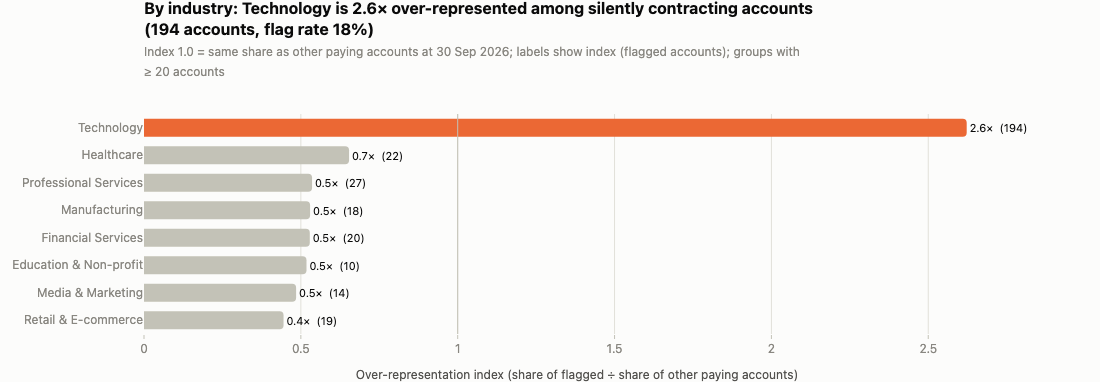

In [8]:
prof = marts.load("silent_churn__profile")
show(SC.fig_overrepresentation(prof, "industry"))

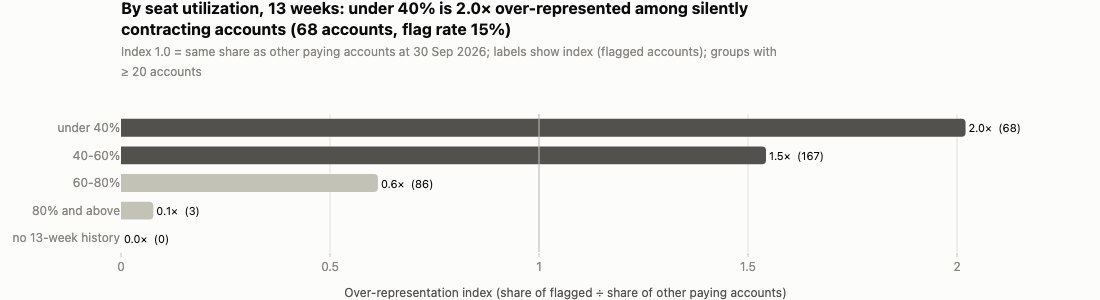

In [9]:
show(SC.fig_overrepresentation(prof, "utilization_band"))

In [10]:
keep = prof[prof["dimension"].isin(["segment", "billing_period", "plan_id", "tenure_band", "cs_coverage", "acquisition_channel"])]
keep[["dimension_label", "value", "flagged", "other", "share_flagged", "share_other", "index", "flag_rate"]].reset_index(drop=True)

,dimension_label,value,flagged,other,share_flagged,share_other,index,flag_rate
0,Segment,SMB,236,2525,0.7284,0.6657,1.0942,0.0855
1,Segment,Mid-Market,77,1091,0.2377,0.2876,0.8262,0.0659
2,Segment,Enterprise,11,177,0.0340,0.0467,0.7275,0.0585
3,Acquisition channel,Organic,113,1147,0.3488,0.3024,1.1533,0.0897
4,Acquisition channel,Paid Social,45,484,0.1389,0.1276,1.0884,0.0851
5,Acquisition channel,Paid Search,71,850,0.2191,0.2241,0.9779,0.0771
6,Acquisition channel,Events,27,327,0.0833,0.0862,0.9666,0.0763
7,Acquisition channel,Partner,36,500,0.1111,0.1318,0.8429,0.0672
8,Acquisition channel,Outbound Sales,32,485,0.0988,0.1279,0.7724,0.0619
9,Plan,basic,233,2199,0.7191,0.5798,1.2404,0.0958


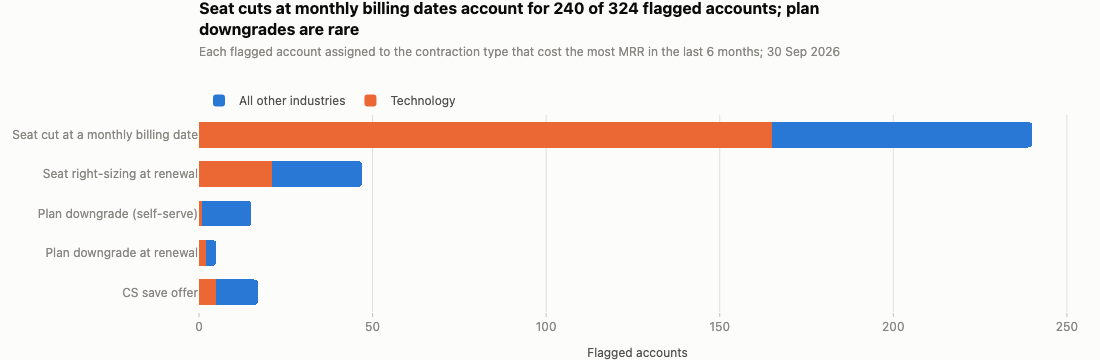

,kind,group,accounts,mrr_lost
0,Seat cut at a monthly billing date,All other industries,75,"3,627.0000"
1,Seat cut at a monthly billing date,Technology,165,"11,035.0000"
2,Seat right-sizing at renewal,All other industries,26,"8,814.7400"
3,Seat right-sizing at renewal,Technology,21,"11,708.5800"
4,Plan downgrade (self-serve),All other industries,14,"3,075.0000"
5,Plan downgrade (self-serve),Technology,1,780.0000
6,Plan downgrade at renewal,All other industries,3,720.0000
7,Plan downgrade at renewal,Technology,2,"1,462.0000"
8,CS save offer,All other industries,12,"9,474.0000"
9,CS save offer,Technology,5,"2,593.6800"


In [11]:
mix = marts.load("silent_churn__contraction_mix")
show(SC.fig_contraction_mix(mix))
mix

In [12]:
md(f"""**Reading.** Technology accounts are {P['technology_index']:.1f}× over-represented ({P['technology_flagged_accounts']} of {k['flagged_accounts']} flagged accounts; flag rate
{pct(P['technology_flag_rate'], 1)} vs {pct(P['other_flag_rate'], 1)} elsewhere). Monthly-billed accounts ({P['monthly_billing_index']:.1f}×) and Basic-plan accounts ({P['basic_plan_index']:.1f}×) are
over-represented because they can cut seats at any billing date; Enterprise ({P['enterprise_index']:.1f}×) and annual contracts are under-represented because they can only shrink at renewal —
their contraction is still ahead of them (section 4). Accounts with utilization under 40% are {P['utilization_under_40_index']:.1f}× over-represented and those whose WAU fell 30%+ are
{P['wau_down_30_index']:.1f}×: usage after the cut reflects the smaller team. By type, {k['contraction_mix']['seat_cut_monthly_accounts']} accounts cut seats at a monthly billing date,
{k['contraction_mix']['seat_rightsize_renewal_accounts']} right-sized at an annual renewal, {k['contraction_mix']['plan_downgrade_accounts']} downgraded the plan and
{k['contraction_mix']['cs_save_accounts']} took a CS save offer. This matches the CSM anecdote ("Technology customers trimming seats"): the data shows it is concentrated, large
(median cut {pct(k['contraction_mix']['median_seat_cut_pct'], 0)} of seats) and arrived from July 2026 at monthly billing dates — consistent with the headcount explanation CSMs give; billing and usage data cannot tell headcount cuts apart from product dissatisfaction or other causes.
Correlation with the sector, not a measured cause: we observe no account-level headcount data.""")

**Reading.** Technology accounts are 2.6× over-represented (194 of 324 flagged accounts; flag rate
18.3% vs 4.3% elsewhere). Monthly-billed accounts (1.5×) and Basic-plan accounts (1.2×) are
over-represented because they can cut seats at any billing date; Enterprise (0.7×) and annual contracts are under-represented because they can only shrink at renewal —
their contraction is still ahead of them (section 4). Accounts with utilization under 40% are 2.0× over-represented and those whose WAU fell 30%+ are
2.3×: usage after the cut reflects the smaller team. By type, 240 accounts cut seats at a monthly billing date,
47 right-sized at an annual renewal, 20 downgraded the plan and
17 took a CS save offer. This matches the CSM anecdote ("Technology customers trimming seats"): the data shows it is concentrated, large
(median cut 25% of seats) and arrived from July 2026 at monthly billing dates — consistent with the headcount explanation CSMs give; billing and usage data cannot tell headcount cuts apart from product dissatisfaction or other causes.
Correlation with the sector, not a measured cause: we observe no account-level headcount data.

### 3. What happens next to silently contracting accounts?

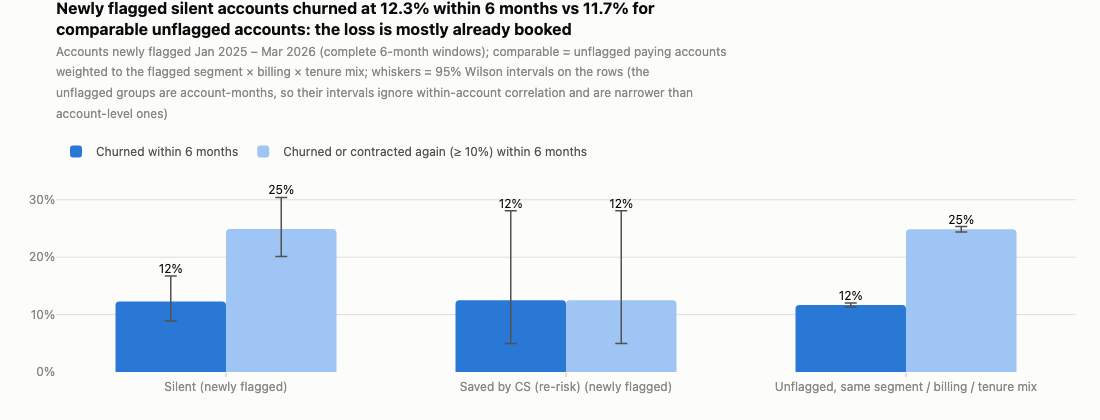

,label,n,churn_6m,churn_6m_lo,churn_6m_hi,loss_6m,loss_6m_lo,loss_6m_hi
0,Silent (newly flagged),269,0.1227,0.0887,0.1673,0.2491,0.2012,0.3040
1,Saved by CS (re-risk) (newly flagged),32,0.1250,0.0497,0.2807,0.1250,0.0497,0.2807
2,"Unflagged, same segment / billing / tenure mix",32839,0.1166,0.1132,0.1201,0.2485,0.2439,0.2532
3,"Unflagged, all paying accounts",32839,0.0935,0.0904,0.0967,0.1881,0.1839,0.1924


In [13]:
fu = marts.load("silent_churn__followup")
show(SC.fig_followup(fu))
fu[["label", "n", "churn_6m", "churn_6m_lo", "churn_6m_hi", "loss_6m", "loss_6m_lo", "loss_6m_hi"]]

In [14]:
md(f"""**Reading.** Of {F['silent_n']} accounts newly flagged as silent between Jan 2025 and Mar 2026, {pct(F['silent_churn_6m'], 1)} churned within 6 months
(95% interval {pct(F['silent_churn_6m_lo'], 1)}–{pct(F['silent_churn_6m_hi'], 1)}) and {pct(F['silent_loss_6m'], 1)} churned or contracted again by ≥ 10%.
Unflagged accounts with the same segment, billing and tenure mix: {pct(F['unflagged_matched_churn_6m'], 1)} and {pct(F['unflagged_matched_loss_6m'], 1)} (raw, all unflagged:
{pct(F['unflagged_raw_churn_6m'], 1)} and {pct(F['unflagged_raw_loss_6m'], 1)}). The intervals overlap: a silent contraction is not a strong predictor of *logo* churn in this data —
the revenue was lost when the seats went. CS-saved accounts ({F['saved_re_risk_n']} events) churned at {pct(F['saved_re_risk_churn_6m'], 0)}
({pct(F['saved_re_risk_churn_6m_lo'], 0)}–{pct(F['saved_re_risk_churn_6m_hi'], 0)}): too few to say more than "not obviously worse". These rates are the hit rates used for
ARR at stake in the watchlist, and they come from before the Technology layoff wave, whose accounts have not yet had 6 months of follow-up.
The whiskers are Wilson intervals on the rows: one row per newly flagged account for the flagged groups, but {F['unflagged_matched_n']:,} account-months from far fewer accounts
for the comparison, so the comparison's interval ignores within-account correlation and is narrower than an account-level interval would be.""")

**Reading.** Of 269 accounts newly flagged as silent between Jan 2025 and Mar 2026, 12.3% churned within 6 months
(95% interval 8.9%–16.7%) and 24.9% churned or contracted again by ≥ 10%.
Unflagged accounts with the same segment, billing and tenure mix: 11.7% and 24.9% (raw, all unflagged:
9.4% and 18.8%). The intervals overlap: a silent contraction is not a strong predictor of *logo* churn in this data —
the revenue was lost when the seats went. CS-saved accounts (32 events) churned at 12%
(5%–28%): too few to say more than "not obviously worse". These rates are the hit rates used for
ARR at stake in the watchlist, and they come from before the Technology layoff wave, whose accounts have not yet had 6 months of follow-up.
The whiskers are Wilson intervals on the rows: one row per newly flagged account for the flagged groups, but 32,839 account-months from far fewer accounts
for the comparison, so the comparison's interval ignores within-account correlation and is narrower than an account-level interval would be.

### 4. Can we see it coming? Early-warning back-test

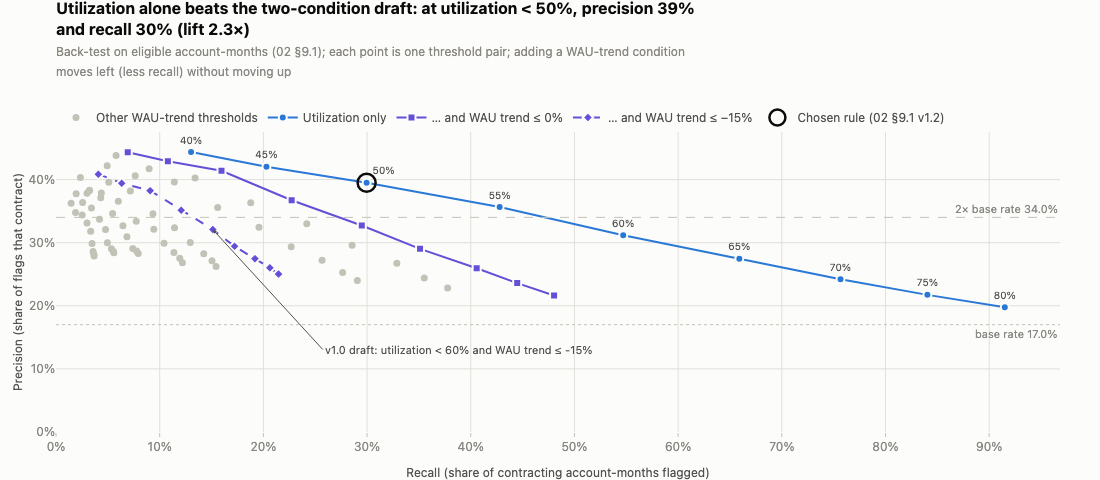

In [15]:
grid = marts.load("silent_churn__backtest_grid")
show(SC.fig_pr_tradeoff(grid))

In [16]:
cols = ["utilization_threshold", "wau_trend_threshold", "flagged_rows", "precision", "recall", "lift", "flags_per_month", "csm_flags_per_month",
        "csm_accounts_per_quarter", "event_recall", "account_recall", "lead_median", "share_lead_ge2", "passes_precision", "passes_capacity", "chosen", "doc_default"]
grid.loc[grid["wau_trend_threshold"].isna() | grid["doc_default"] | (grid["wau_trend_threshold"].isin([0.0, -0.15]) & grid["utilization_threshold"].isin([0.5, 0.55, 0.6])), cols].reset_index(drop=True)

,utilization_threshold,wau_trend_threshold,flagged_rows,precision,recall,lift,flags_per_month,csm_flags_per_month,csm_accounts_per_quarter,event_recall,account_recall,lead_median,share_lead_ge2,passes_precision,passes_capacity,chosen,doc_default
0,0.4000,NaN,1510,0.4437,0.1302,2.6090,86.8333,20.1667,31.0000,0.1647,0.1713,3.0000,0.7930,True,True,False,False
1,0.4500,NaN,2483,0.4205,0.2030,2.4723,138.0000,31.8333,48.0000,0.2474,0.2533,3.0000,0.8271,True,True,False,False
2,0.5000,NaN,3902,0.3949,0.2996,2.3222,216.7500,54.5000,87.5000,0.3566,0.3622,3.0000,0.8298,True,True,True,False
3,0.5000,0.0000,1983,0.4140,0.1596,2.4345,110.7500,29.1667,63.5000,0.2838,0.2920,2.0000,0.7271,True,True,False,False
4,0.5000,-0.1500,1221,0.3825,0.0908,2.2490,68.8333,12.4167,34.0000,0.2075,0.2172,2.0000,0.6602,True,True,False,False
5,0.5500,NaN,6175,0.3564,0.4279,2.0959,340.9167,82.5000,127.0000,0.4827,0.4882,4.0000,0.8575,True,False,False,False
6,0.5500,0.0000,3183,0.3673,0.2273,2.1595,175.9167,42.9167,91.2500,0.3873,0.3983,2.0000,0.7343,True,True,False,False
7,0.5500,-0.1500,1767,0.3514,0.1207,2.0665,98.9167,17.2500,47.0000,0.2699,0.2848,2.0000,0.6702,True,True,False,False
8,0.6000,NaN,9028,0.3117,0.5470,1.8328,484.6667,119.2500,179.7500,0.5919,0.5906,4.0000,0.8779,False,False,False,False
9,0.6000,0.0000,4636,0.3272,0.2949,1.9241,249.7500,60.5000,128.0000,0.4919,0.5000,2.0000,0.7556,False,False,False,False


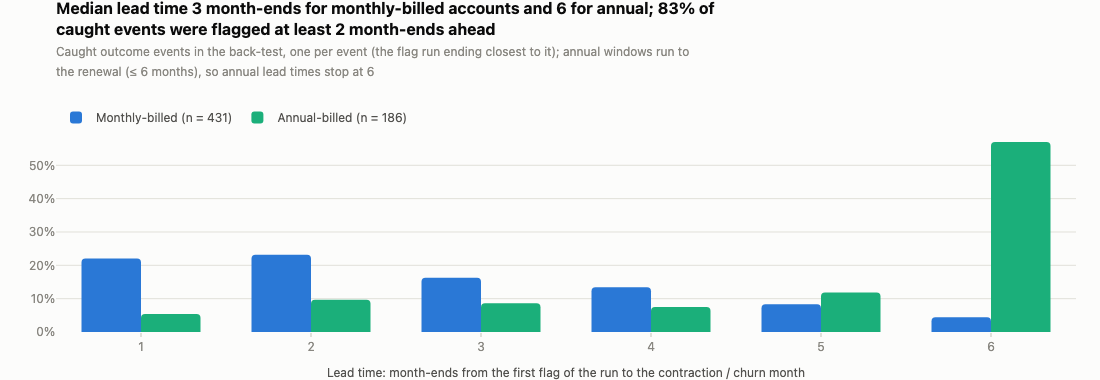

In [17]:
show(SC.fig_lead_time(marts.load("silent_churn__lead_times")))

In [18]:
bb = marts.load("silent_churn__rule_by_billing")
bb[["rule", "billing_period", "eligible_rows", "base_rate", "flagged_rows", "precision", "recall", "lift", "flags_per_month", "csm_flags_per_month",
    "event_recall", "account_recall", "lead_median", "lead_p25", "lead_p75", "share_lead_ge2"]]

,rule,billing_period,eligible_rows,base_rate,flagged_rows,precision,recall,lift,flags_per_month,csm_flags_per_month,event_recall,account_recall,lead_median,lead_p25,lead_p75,share_lead_ge2
0,chosen,monthly,21257,0.1450,2558,0.3190,0.2648,2.2002,145.4167,18.8333,0.3219,0.3262,3.0000,2.0000,4.0000,0.7773
1,chosen,annual,8990,0.2294,1344,0.5394,0.3516,2.3519,71.3333,35.6667,0.4808,0.4781,6.0000,4.0000,6.0000,0.9468
2,chosen,all,30247,0.1701,3902,0.3949,0.2996,2.3222,216.7500,54.5000,0.3566,0.3622,3.0000,2.0000,6.0000,0.8298
3,doc_default,monthly,21257,0.1450,1776,0.2736,0.1577,1.8874,99.5833,10.3333,0.2972,0.3159,2.0000,1.0000,3.0000,0.6231
4,doc_default,annual,8990,0.2294,649,0.4499,0.1416,1.9616,33.9167,13.0000,0.4808,0.4863,3.0000,2.0000,5.0000,0.8617
5,doc_default,all,30247,0.1701,2425,0.3208,0.1512,1.8865,133.5000,23.3333,0.3387,0.3570,2.0000,1.0000,3.0000,0.6997


In [19]:
bq = marts.load("silent_churn__rule_by_quarter")
bq = bq[bq["rule"] == "chosen"]
bq[["quarter_label", "eligible_rows", "positives", "base_rate", "flagged_rows", "true_positives", "precision", "recall", "lift", "csm_accounts"]].reset_index(drop=True)

,quarter_label,eligible_rows,positives,base_rate,flagged_rows,true_positives,precision,recall,lift,csm_accounts
0,2024-Q3,1725,249,0.1443,226,80,0.3540,0.3213,2.4523,30
1,2024-Q4,2126,307,0.1444,239,112,0.4686,0.3648,3.2452,34
2,2025-Q1,2553,395,0.1547,307,124,0.4039,0.3139,2.6106,38
3,2025-Q2,3212,522,0.1625,339,140,0.4130,0.2682,2.5412,48
4,2025-Q3,4007,624,0.1557,608,198,0.3257,0.3173,2.0912,86
5,2025-Q4,4591,793,0.1727,558,222,0.3978,0.2799,2.3033,90
6,2026-Q1,5100,831,0.1629,735,292,0.3973,0.3514,2.4382,100
7,2026-Q2,5246,1156,0.2204,700,297,0.4243,0.2569,1.9254,74


In [20]:
marts.load("silent_churn__rule_bootstrap")[["billing_period", "accounts", "rows", "precision", "precision_lo", "precision_hi",
                                              "recall", "recall_lo", "recall_hi", "n_boot"]]

,billing_period,accounts,rows,precision,precision_lo,precision_hi,recall,recall_lo,recall_hi,n_boot
0,monthly,2349,21257,0.3190,0.2919,0.3473,0.2648,0.2414,0.2922,1000
1,annual,1141,8990,0.5394,0.4869,0.5959,0.3516,0.3113,0.3939,1000
2,all,3350,30247,0.3949,0.3692,0.4228,0.2996,0.2775,0.3233,1000


In [21]:
m, a = R["by_billing_period"]["monthly"], R["by_billing_period"]["annual"]
dm, da = D["by_billing_period"]["monthly"], D["by_billing_period"]["annual"]
u55 = grid[(grid["utilization_threshold"] == 0.55) & grid["wau_trend_threshold"].isna()].iloc[0]
md(f"""**Reading.** On {R['eligible_rows']:,} eligible account-months ({R['positives']:,} with an outcome, base rate {pct(R['base_rate'], 1)}), the chosen rule
**13-week seat utilization below {pct(R['utilization_threshold'], 0)}** flags {R['flagged_rows']:,} account-months with precision {pct(R['precision'], 1)}
(95% interval {pct(R['precision_lo'], 1)}–{pct(R['precision_hi'], 1)}), recall {pct(R['recall'], 1)} ({pct(R['recall_lo'], 1)}–{pct(R['recall_hi'], 1)}) and lift {R['lift']:.2f}×.
The intervals come from an account-level bootstrap ({R['bootstrap_resamples']:,} resamples of {R['bootstrap_accounts']:,} accounts, each account's month-ends drawn together):
each account contributes about {R['eligible_rows'] / R['bootstrap_accounts']:.0f} rows, so a row-level interval would be too narrow. It catches {pct(R['event_recall'], 0)} of
loss events (contractions or cancellations; {R['events_caught']:,} of {R['events']:,}; one run per event, the run ending closest to the outcome) and {pct(R['account_recall'], 0)} of accounts that later contract or cancel.
Lead time: median {m['lead_median']:.0f} month-ends for monthly-billed and {a['lead_median']:.0f} for annual-billed accounts, and {pct(R['share_lead_ge2'], 0)} of caught events were
flagged at least 2 month-ends ahead; the pooled median is {R['lead_median']:.0f} (quartiles {R['lead_p25']:.0f}–{R['lead_p75']:.0f}), but it moves with the monthly / annual mix, so
the by-billing medians are the figures to quote. Volume: about {R['flags_per_month']:.0f} flags a month, {R['csm_accounts_per_quarter']:.0f} distinct CSM-covered accounts a quarter —
within the 120-review capacity.

*Stable quarter by quarter.* The chosen rule's precision is {pct(Q['precision_min'], 0)}–{pct(Q['precision_max'], 0)} and recall {pct(Q['recall_min'], 0)}–{pct(Q['recall_max'], 0)} in every quarter from {Q['first_quarter']} to
{Q['last_quarter']} (base rate {pct(Q['base_rate_min'], 0)}–{pct(Q['base_rate_max'], 0)}, lift never below {Q['lift_min']:.1f}×).
The per-quarter results show the rule is stable over time; it was chosen and scored on the same back-test, so some selection optimism remains — the frozen rule should be checked on Q4 2026 onward.

*Why utilization only.* Adding the WAU-trend condition moves every point left on the trade-off chart without moving it up: at utilization < {pct(R['utilization_threshold'], 0)}, requiring WAU ≤ 0% raises
precision by less than 2 points and halves recall; requiring ≤ −15% lowers precision. The 4-week WAU average is noisy at small team sizes, while 13-week utilization directly
measures "more seats than people". The v1.0 draft (utilization < 60% and WAU trend ≤ −15%) scores precision {pct(D['precision'], 1)}, recall {pct(D['recall'], 1)}, lift {D['lift']:.2f}×
(below the 2× bar) and a median lead of {D['lead_median']:.0f} month-ends. Utilization < 55% would lift recall to {pct(float(u55['recall']), 0)}
but flags {u55['csm_accounts_per_quarter']:.0f} CSM-covered accounts a quarter, over capacity.
**02 §9.1 (v1.2) therefore reads "utilization < {pct(R['utilization_threshold'], 0)}" with no WAU condition; the WAU drop is kept as a reason code.** Most outcomes are still not caught
({pct(1 - R['event_recall'], 0)} of events): the rule prioritises the CSM queue, it does not predict churn.

*By billing period.* Monthly-billed: precision {pct(m['precision'], 1)} ({pct(m['precision_lo'], 1)}–{pct(m['precision_hi'], 1)}), recall {pct(m['recall'], 1)}, lift {m['lift']:.2f}×,
median lead {m['lead_median']:.0f} month-ends. Annual-billed: precision {pct(a['precision'], 1)} ({pct(a['precision_lo'], 1)}–{pct(a['precision_hi'], 1)}), recall {pct(a['recall'], 1)},
lift {a['lift']:.2f}×, median lead {a['lead_median']:.0f} (the window runs to the renewal, so the lead is capped at 6). Annual accounts flag with higher precision because an under-used
annual contract is very likely to be right-sized at renewal — which is exactly when a CSM can still act.
The v1.0 draft by billing period (precision / recall): monthly {pct(dm['precision'], 1)} / {pct(dm['recall'], 1)}, annual {pct(da['precision'], 1)} / {pct(da['recall'], 1)}.""")

**Reading.** On 30,247 eligible account-months (5,144 with an outcome, base rate 17.0%), the chosen rule
**13-week seat utilization below 50%** flags 3,902 account-months with precision 39.5%
(95% interval 36.9%–42.3%), recall 30.0% (27.7%–32.3%) and lift 2.32×.
The intervals come from an account-level bootstrap (1,000 resamples of 3,350 accounts, each account's month-ends drawn together):
each account contributes about 9 rows, so a row-level interval would be too narrow. It catches 36% of
loss events (contractions or cancellations; 617 of 1,730; one run per event, the run ending closest to the outcome) and 36% of accounts that later contract or cancel.
Lead time: median 3 month-ends for monthly-billed and 6 for annual-billed accounts, and 83% of caught events were
flagged at least 2 month-ends ahead; the pooled median is 3 (quartiles 2–6), but it moves with the monthly / annual mix, so
the by-billing medians are the figures to quote. Volume: about 217 flags a month, 88 distinct CSM-covered accounts a quarter —
within the 120-review capacity.

*Stable quarter by quarter.* The chosen rule's precision is 33%–47% and recall 26%–36% in every quarter from Q3 2024 to
Q2 2026 (base rate 14%–22%, lift never below 1.9×).
The per-quarter results show the rule is stable over time; it was chosen and scored on the same back-test, so some selection optimism remains — the frozen rule should be checked on Q4 2026 onward.

*Why utilization only.* Adding the WAU-trend condition moves every point left on the trade-off chart without moving it up: at utilization < 50%, requiring WAU ≤ 0% raises
precision by less than 2 points and halves recall; requiring ≤ −15% lowers precision. The 4-week WAU average is noisy at small team sizes, while 13-week utilization directly
measures "more seats than people". The v1.0 draft (utilization < 60% and WAU trend ≤ −15%) scores precision 32.1%, recall 15.1%, lift 1.89×
(below the 2× bar) and a median lead of 2 month-ends. Utilization < 55% would lift recall to 43%
but flags 127 CSM-covered accounts a quarter, over capacity.
**02 §9.1 (v1.2) therefore reads "utilization < 50%" with no WAU condition; the WAU drop is kept as a reason code.** Most outcomes are still not caught
(64% of events): the rule prioritises the CSM queue, it does not predict churn.

*By billing period.* Monthly-billed: precision 31.9% (29.2%–34.7%), recall 26.5%, lift 2.20×,
median lead 3 month-ends. Annual-billed: precision 53.9% (48.7%–59.6%), recall 35.2%,
lift 2.35×, median lead 6 (the window runs to the renewal, so the lead is capped at 6). Annual accounts flag with higher precision because an under-used
annual contract is very likely to be right-sized at renewal — which is exactly when a CSM can still act.
The v1.0 draft by billing period (precision / recall): monthly 27.4% / 15.8%, annual 45.0% / 14.2%.

### 5. The watchlist

In [22]:
wl = marts.load("silent_churn__watchlist")
cols = ["priority_rank", "priority_tier", "queue", "customer_id", "company_name", "segment", "industry", "csm_owner", "plan", "billing_period", "seats", "current_arr",
        "arr_at_stake", "next_renewal_date", "days_to_renewal", "flag_source", "reason_code_1", "reason_code_2", "reason_code_3", "suggested_play"]
wl[wl["queue"] == "csm"][cols].head(15)

,priority_rank,priority_tier,queue,customer_id,company_name,segment,industry,csm_owner,plan,billing_period,seats,current_arr,arr_at_stake,next_renewal_date,days_to_renewal,flag_source,reason_code_1,reason_code_2,reason_code_3,suggested_play
0,1,1,csm,CUS-000016,Juniperforge AI,Mid-Market,Technology,CSM-08,premium,annual,25,"7,728.0000","4,168.7500",2026-10-04,4,early_warning,UTIL_BELOW_50,RENEWAL_WITHIN_120D,,Urgent — renews in 4 days: Pre-renewal utiliza...
1,2,1,csm,CUS-001247,Lumenscale Media,Mid-Market,Media & Marketing,CSM-10,premium,annual,48,"16,128.0000","8,700.0000",2026-10-04,4,early_warning,UTIL_BELOW_50,RENEWAL_WITHIN_120D,,Urgent — renews in 4 days: Pre-renewal utiliza...
2,3,1,csm,CUS-000041,Coralwave Systems,Mid-Market,Technology,CSM-06,premium,annual,30,"10,080.0000","5,437.5000",2026-10-08,8,early_warning,UTIL_BELOW_50,WAU_DOWN_15PCT,RENEWAL_WITHIN_120D,Urgent — renews in 8 days: Pre-renewal utiliza...
3,4,1,csm,CUS-002887,Everwood Advisory,Mid-Market,Professional Services,CSM-08,basic,annual,13,"1,872.0000","1,009.8214",2026-10-10,10,early_warning,UTIL_BELOW_50,WAU_UP_20PCT,RENEWAL_WITHIN_120D,Urgent — renews in 10 days: Usage is growing i...
4,5,1,csm,CUS-002888,Junipervale Software,Mid-Market,Technology,CSM-08,enterprise,annual,65,"30,030.0000","16,199.2188",2026-10-10,10,early_warning,UTIL_BELOW_50,RENEWAL_WITHIN_120D,,Urgent — renews in 10 days: Pre-renewal utiliz...
5,6,1,csm,CUS-002910,Mapleview Wealth,Mid-Market,Financial Services,CSM-09,basic,annual,14,"2,016.0000","1,087.5000",2026-10-13,13,early_warning,UTIL_BELOW_50,WAU_DOWN_15PCT,RENEWAL_WITHIN_120D,Urgent — renews in 13 days: Pre-renewal utiliz...
6,7,1,csm,CUS-001311,Maplebridge AI,Mid-Market,Technology,CSM-05,premium,annual,21,"7,056.0000","3,806.2500",2026-10-18,18,early_warning,UTIL_BELOW_50,RENEWAL_WITHIN_120D,,Urgent — renews in 18 days: Pre-renewal utiliz...
7,8,1,csm,CUS-000099,Swiftspark Learning,Mid-Market,Education & Non-profit,CSM-07,premium,annual,19,"6,384.0000","3,443.7500",2026-10-21,21,early_warning,UTIL_BELOW_50,WAU_UP_20PCT,RENEWAL_WITHIN_120D,Urgent — renews in 21 days: Usage is growing i...
8,9,1,csm,CUS-002968,Cedarloop Consulting,Mid-Market,Professional Services,CSM-07,basic,annual,23,"3,312.0000","1,786.6071",2026-10-22,22,early_warning,UTIL_BELOW_50,RENEWAL_WITHIN_120D,,Urgent — renews in 22 days: Pre-renewal utiliz...
9,10,1,csm,CUS-002984,Juniperwave Labs,Mid-Market,Technology,CSM-10,basic,annual,19,"2,736.0000","1,475.8929",2026-10-23,23,early_warning,UTIL_BELOW_50,WAU_UP_20PCT,RENEWAL_WITHIN_120D,Urgent — renews in 23 days: Usage is growing i...


In [23]:
wl.groupby(["queue", "flag_source"]).agg(accounts=("customer_id", "size"), current_arr=("current_arr", "sum"), arr_at_stake=("arr_at_stake", "sum"),
                                       renewals_120d=("renewal_within_120d", "sum")).round(0)

accounts    current_arr   arr_at_stake  renewals_120d
queue   flag_source                                                                         
csm     early_warning                       194 2,326,472.0000 1,194,166.0000             62
        saved_re_risk                         7    27,468.0000     3,434.0000              0
        saved_re_risk + early_warning         4    57,216.0000    30,229.0000              0
        silent                               75   704,443.0000   175,456.0000              0
        silent + early_warning                2    19,968.0000    10,771.0000              0
digital early_warning                       471   615,360.0000   256,134.0000             72
        saved_re_risk                         6     5,616.0000       702.0000              0
        silent                              215   235,860.0000    58,746.0000              0
        silent + early_warning               15    19,620.0000     6,894.0000              0

In [24]:
bp = W["bucket_precision"]
md(f"""**Reading.** {W['accounts']:,} accounts: {W['silent_or_saved']:,} from the §9 definition, {W['early_warning']:,} from the early-warning rule, {W['both']} on both. Together they
pay {money(W['current_arr'])} ARR; **ARR at stake {money(W['arr_at_stake'])}** using hit rates of {pct(bp['early_warning_monthly'], 0)} (rule, monthly-billed),
{pct(bp['early_warning_annual'], 0)} (rule, annual-billed), {pct(bp['silent'], 0)} (silent) and {pct(bp['saved_re_risk'], 0)} (saved). {W['csm_queue']:,} accounts are CSM-covered;
the top {SC.CSM_CAPACITY_PER_QUARTER} by priority hold {money(W['top120_csm_arr_at_stake'])}, **{pct(W['top120_csm_share_of_arr_at_stake'], 0)} of all ARR at stake** and
{pct(W['top120_csm_share_of_csm_arr_at_stake'], 0)} of the CSM queue's — above the 60% trigger, so the Q1 2027 plan is CSM-led reviews for that queue and the digital play for the
{W['digital_queue']:,} digital accounts. {W['renewals_within_120d']} annual renewals ({money(W['renewal_arr_within_120d'])} ARR) fall within 120 days and lead each queue in three tiers: renewals in under
{W['urgent_renewal_days']} days by date ({W['renewals_under_45d']} accounts, soonest first), renewals in {W['urgent_renewal_days']}–120 days by ARR at stake, then the rest by ARR at stake —
so a CSM working top-down reaches a renewal before its date passes. Of the first {SC.CSM_CAPACITY_PER_QUARTER} CSM-covered accounts, {W['top120_csm_rising_usage']}
({pct(W['top120_csm_rising_usage'] / SC.CSM_CAPACITY_PER_QUARTER, 0)}) have WAU up {pct(SC.WAU_UP_CODE, 0)} or more on under-used seats: their play is a seat-count conversation
before renewal (confirm team size and seat count, no discount), not an idle-seat save, and the evidence column says so.
Reason codes: {"; ".join(f"`{c}` = {t}" for c, t in SC.REASON_CODES.items())}. The full list is `silent_churn__watchlist` in the parquet cache and the risk part of
`docs/account_health_list.csv`.""")

**Reading.** 989 accounts: 324 from the §9 definition, 686 from the early-warning rule, 21 on both. Together they
pay $4.0M ARR; **ARR at stake $1.7M** using hit rates of 32% (rule, monthly-billed),
54% (rule, annual-billed), 25% (silent) and 12% (saved). 282 accounts are CSM-covered;
the top 120 by priority hold $1.1M, **66% of all ARR at stake** and
81% of the CSM queue's — above the 60% trigger, so the Q1 2027 plan is CSM-led reviews for that queue and the digital play for the
707 digital accounts. 134 annual renewals ($822K ARR) fall within 120 days and lead each queue in three tiers: renewals in under
45 days by date (32 accounts, soonest first), renewals in 45–120 days by ARR at stake, then the rest by ARR at stake —
so a CSM working top-down reaches a renewal before its date passes. Of the first 120 CSM-covered accounts, 23
(19%) have WAU up 20% or more on under-used seats: their play is a seat-count conversation
before renewal (confirm team size and seat count, no discount), not an idle-seat save, and the evidence column says so.
Reason codes: `SPEND_DOWN_20PCT_6M` = billing-neutral MRR is at least 20% below its peak of the previous 6 month-ends, after a seat, plan or discount contraction (the §9 silent-contraction flag); `SEATS_CUT_20PCT_6M` = seats are at least 20% below the peak seat count of the previous 6 month-ends; `DOWNGRADED_6M` = the plan tier was lowered in the last 6 months; `RENEWAL_RIGHTSIZED_6M` = the contraction was taken at an annual renewal (seats or plan); `SAVED_BY_CS_6M` = the contraction was a CS save offer: the account asked to cancel and was kept on smaller terms; `UTIL_BELOW_50` = seat utilization over the last 13 complete weeks is below 50% (the early-warning rule); `WAU_DOWN_15PCT` = weekly active users in the last 4 weeks are at least 15% below the previous 9 weeks (context); `WAU_UP_20PCT` = weekly active users in the last 4 weeks are at least 20% above the previous 9 weeks — usage is growing into the seats (context; with an early-warning flag the play is a seat-count conversation, not an idle-seat save); `RENEWAL_WITHIN_120D` = the annual term ends within 120 days. The full list is `silent_churn__watchlist` in the parquet cache and the risk part of
`docs/account_health_list.csv`.

## Limitations

In [25]:
md(f"""- **Synthetic data.** Effect sizes follow the generator's rules (`docs/data_model.md §5–6`); the method transfers, the magnitudes do not.
- **Follow-up rates predate the Technology wave.** The 6-month churn and hit rates for silent accounts come from Jan 2025 – Mar 2026; the current list is {pct(P['technology_share_flagged'], 0)} Technology, whose next six months are not observed yet. ARR at stake for those accounts is an extrapolation.
- **Row-level precision penalises early flags.** A flag four month-ends before a monthly-billed account's contraction counts as a false positive (its window is three months). Event-level recall and the lead-time distribution are the complementary view; the two should be read together.
- **Selection and evaluation share the same rows.** The operating point was picked on the grid it is scored on. The criterion was fixed in advance and the per-quarter check (precision {pct(Q['precision_min'], 0)}–{pct(Q['precision_max'], 0)}, recall {pct(Q['recall_min'], 0)}–{pct(Q['recall_max'], 0)} over {Q['quarters']} quarters) limits the optimism, but a clean out-of-sample test needs quarters not used for the selection.
- **Intervals.** Precision and recall carry account-level bootstrap intervals ({pct(R['precision_lo'], 0)}–{pct(R['precision_hi'], 0)} and {pct(R['recall_lo'], 0)}–{pct(R['recall_hi'], 0)}); the follow-up comparison's Wilson intervals are on account-month rows and are narrower than account-level ones.
- **Annual lead times are capped at 6** by the eligibility window (renewal within 6 months), and the rule needs 13 complete weeks of usage, so accounts younger than three months are not covered (they belong to the onboarding program).
- **No open cancellations at the as-of date.** The generator records cancellations only at billing dates it has processed, so the "no open cancellation" exclusion changes nothing on the current list; in production it would remove accounts already in the churn report.
- **Small samples.** CS-saved accounts: {F['saved_re_risk_n']} events, interval {pct(F['saved_re_risk_churn_6m_lo'], 0)}–{pct(F['saved_re_risk_churn_6m_hi'], 0)}. Technology-only follow-up is not estimable yet.
- **Correlation, not causation.** Low utilization precedes contraction; nothing here shows that raising utilization prevents it. The Technology link is a sector correlation (no account-level headcount data). A holdout test of the CS plays is the only clean answer.
- **CS capacity is an assumption** (A9: {SC.CSM_CAPACITY_PER_QUARTER} reviews a quarter); the cut-off moves with it, the ranking does not.""")

- **Synthetic data.** Effect sizes follow the generator's rules (`docs/data_model.md §5–6`); the method transfers, the magnitudes do not.
- **Follow-up rates predate the Technology wave.** The 6-month churn and hit rates for silent accounts come from Jan 2025 – Mar 2026; the current list is 60% Technology, whose next six months are not observed yet. ARR at stake for those accounts is an extrapolation.
- **Row-level precision penalises early flags.** A flag four month-ends before a monthly-billed account's contraction counts as a false positive (its window is three months). Event-level recall and the lead-time distribution are the complementary view; the two should be read together.
- **Selection and evaluation share the same rows.** The operating point was picked on the grid it is scored on. The criterion was fixed in advance and the per-quarter check (precision 33%–47%, recall 26%–36% over 8 quarters) limits the optimism, but a clean out-of-sample test needs quarters not used for the selection.
- **Intervals.** Precision and recall carry account-level bootstrap intervals (37%–42% and 28%–32%); the follow-up comparison's Wilson intervals are on account-month rows and are narrower than account-level ones.
- **Annual lead times are capped at 6** by the eligibility window (renewal within 6 months), and the rule needs 13 complete weeks of usage, so accounts younger than three months are not covered (they belong to the onboarding program).
- **No open cancellations at the as-of date.** The generator records cancellations only at billing dates it has processed, so the "no open cancellation" exclusion changes nothing on the current list; in production it would remove accounts already in the churn report.
- **Small samples.** CS-saved accounts: 32 events, interval 5%–28%. Technology-only follow-up is not estimable yet.
- **Correlation, not causation.** Low utilization precedes contraction; nothing here shows that raising utilization prevents it. The Technology link is a sector correlation (no account-level headcount data). A holdout test of the CS plays is the only clean answer.
- **CS capacity is an assumption** (A9: 120 reviews a quarter); the cut-off moves with it, the ranking does not.

## Recommendations (detail in `05_recommendations`)

In [26]:
md(f"""1. **Head of CS — Q1 2027 coverage plan.** Work the top {SC.CSM_CAPACITY_PER_QUARTER} CSM-covered watchlist accounts ({pct(W['top120_csm_share_of_arr_at_stake'], 0)} of ARR at stake) as proactive reviews, in tier order: annual renewals in under {W['urgent_renewal_days']} days by date, then renewals within 120 days and the rest by ARR at stake. The {W['top120_csm_rising_usage']} of them with WAU up {pct(SC.WAU_UP_CODE, 0)}+ on under-used seats get a seat-count conversation (confirm team size, no discount), not a save. Put the digital queue on the in-app utilization nudge + pre-renewal email sequence. P1: hold out 1 in 5 eligible accounts at random each quarter; compare 6- and 12-month GRR. P2: 50/50 by account; compare 90-day and 12-month billing-neutral contraction + churn between worked and held-out accounts.
2. **RevOps — run the v1.2 rule monthly.** "13-week utilization < {pct(R['utilization_threshold'], 0)}" (precision {pct(R['precision'], 0)}, recall {pct(R['recall'], 0)}, lift {R['lift']:.1f}×; median lead {BM['lead_median']:.0f} month-ends for monthly-billed and {BA['lead_median']:.0f} for annual-billed accounts (the most the back-test window allows)) scored at each month-end close, with "WAU down ≥ 15%" and "WAU up ≥ 20%" as reason codes, not gates. Re-run the back-test each quarter as windows complete — the first clean out-of-sample read — and re-check the operating point against CS capacity.
3. **CS + Sales — Technology seat cuts.** For Technology accounts still above {pct(R['utilization_threshold'], 0)} utilization, run headcount check-ins before the next billing date and offer to lock the remaining seats on annual terms (seat flex in exchange for commitment). Measure the Technology seat-cut rate at billing dates vs the non-Technology rate, quarter over quarter.
4. **CS — silent list is a recovery list.** Flagged accounts do not churn more than peers ({pct(F['silent_churn_6m'], 0)} vs {pct(F['unflagged_matched_churn_6m'], 0)} within 6 months), so the play is to re-earn the lost seats (adoption, re-onboarding) rather than to save the logo; track recovered ARR (seats re-added within 6 months of the cut).

**What data I would want next:** account-level headcount or HRIS-style signals (open roles, employee count refreshes) to separate budget cuts from disengagement; CSM activity logs to measure which plays were run on which accounts; seat-level activity (which seats are idle) so the digital nudge can name them; and the cancellation-request feed in real time, so the "no open cancellation" exclusion works on the live list.""")

1. **Head of CS — Q1 2027 coverage plan.** Work the top 120 CSM-covered watchlist accounts (66% of ARR at stake) as proactive reviews, in tier order: annual renewals in under 45 days by date, then renewals within 120 days and the rest by ARR at stake. The 23 of them with WAU up 20%+ on under-used seats get a seat-count conversation (confirm team size, no discount), not a save. Put the digital queue on the in-app utilization nudge + pre-renewal email sequence. P1: hold out 1 in 5 eligible accounts at random each quarter; compare 6- and 12-month GRR. P2: 50/50 by account; compare 90-day and 12-month billing-neutral contraction + churn between worked and held-out accounts.
2. **RevOps — run the v1.2 rule monthly.** "13-week utilization < 50%" (precision 39%, recall 30%, lift 2.3×; median lead 3 month-ends for monthly-billed and 6 for annual-billed accounts (the most the back-test window allows)) scored at each month-end close, with "WAU down ≥ 15%" and "WAU up ≥ 20%" as reason codes, not gates. Re-run the back-test each quarter as windows complete — the first clean out-of-sample read — and re-check the operating point against CS capacity.
3. **CS + Sales — Technology seat cuts.** For Technology accounts still above 50% utilization, run headcount check-ins before the next billing date and offer to lock the remaining seats on annual terms (seat flex in exchange for commitment). Measure the Technology seat-cut rate at billing dates vs the non-Technology rate, quarter over quarter.
4. **CS — silent list is a recovery list.** Flagged accounts do not churn more than peers (12% vs 12% within 6 months), so the play is to re-earn the lost seats (adoption, re-onboarding) rather than to save the logo; track recovered ARR (seats re-added within 6 months of the cut).

**What data I would want next:** account-level headcount or HRIS-style signals (open roles, employee count refreshes) to separate budget cuts from disengagement; CSM activity logs to measure which plays were run on which accounts; seat-level activity (which seats are idle) so the digital nudge can name them; and the cancellation-request feed in real time, so the "no open cancellation" exclusion works on the live list.